Step 1 (mount google drive)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Step 2 (install)

In [2]:
# Install necessary libraries
!pip install torch torchvision Pillow scikit-learn seaborn matplotlib

Step 3 (import)

In [3]:
# Import all required libraries
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision import models
from PIL import Image
import os
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


Step 4 (Defined Model Architecture)

In [4]:
# Use a simpler approach - just load the ResNet-50 directly
# since your model was saved without the wrapper
model = models.resnet50(pretrained=False)  # Don't load pretrained weights
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 4)  # 4 classes for brain tumor types

print("Model architecture defined!")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Model architecture defined!


Step 5 (select model and weight)

In [37]:
# Define the path to your Google Drive folder
drive_path = "/content/drive/My Drive/"

# List all files in your Google Drive to find the correct path
print("Searching for model files in your Google Drive...")
all_files = []
for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file.endswith('.pth'):
            full_path = os.path.join(root, file)
            all_files.append(full_path)
            print(f"Found: {full_path}")

# Check if we found any model files
if not all_files:
    print("No .pth model files found in your Google Drive!")
    print("Please make sure your model files are in Google Drive.")
else:
    print(f"\nFound {len(all_files)} model files.")

    # Create a mapping of model names to paths
    model_paths = {}
    for i, file_path in enumerate(all_files):
        file_name = os.path.basename(file_path)
        model_paths[str(i+1)] = (file_name, file_path)
        print(f"{i+1}. {file_name}")

    # Get user selection
    while True:
        try:
            selected = input(f"\nEnter the number of the model you want to use (1-{len(all_files)}): ")
            if selected in model_paths:
                selected_model_name, model_path = model_paths[selected]
                break
            else:
                print(f"Please enter a number between 1 and {len(all_files)}")
        except ValueError:
            print("Please enter a valid number")

    print(f"\nSelected model: {selected_model_name}")
    print(f"Model path: {model_path}")

    # Load the selected model
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # Load the model checkpoint
    checkpoint = torch.load(model_path, map_location=device)

    # Check what's in the checkpoint and load appropriately
    if 'model' in checkpoint:
        # If the checkpoint contains a 'model' key, it's the state_dict
        model.load_state_dict(checkpoint['model'])
        print("Loaded model from 'model' key in checkpoint")
    else:
        # The checkpoint is the state_dict itself
        model.load_state_dict(checkpoint)
        print("Loaded model directly from checkpoint")

    model.to(device)
    model.eval()

    print("Model loaded successfully!")

Searching for model files in your Google Drive...
Found: /content/drive/My Drive/ResNet-50 model/resnet50_brain_tumor_best.pth
Found: /content/drive/My Drive/ResNet-50 model/resnet50_brain_tumor_final.pth

Found 2 model files.
1. resnet50_brain_tumor_best.pth
2. resnet50_brain_tumor_final.pth

Enter the number of the model you want to use (1-2): 1

Selected model: resnet50_brain_tumor_best.pth
Model path: /content/drive/My Drive/ResNet-50 model/resnet50_brain_tumor_best.pth
Using device: cuda
Loaded model from 'model' key in checkpoint
Model loaded successfully!


Step 6 (Define Data Transforms and Load Test Data)

In [40]:
# Define the same transforms used during training
data_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Define class names (update based on your dataset)
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Function to load test images
def load_test_data(test_dir):
    test_images = []
    test_labels = []

    for class_idx, class_name in enumerate(class_names):
        class_dir = os.path.join(test_dir, class_name)
        if os.path.exists(class_dir):
            for img_name in os.listdir(class_dir):
                if img_name.endswith(('.png', '.jpg', '.jpeg')):
                    img_path = os.path.join(class_dir, img_name)
                    test_images.append(img_path)
                    test_labels.append(class_idx)

    return test_images, test_labels

# Get path to test data
test_dir = input("Enter the path to your test dataset in Google Drive: ")
# Example: /content/drive/My Drive/Brain_Tumor_Detection/test

test_images, test_labels = load_test_data(test_dir)
print(f"Found {len(test_images)} test images")

Enter the path to your test dataset in Google Drive: /content/drive/My Drive/Kerry_AI(assignment)/Testing/
Found 1311 test images


Step 7 (Run prediction on the test data)

In [41]:
# Function to predict a single image
def predict_image(image_path, model, device):
    image = Image.open(image_path).convert('RGB')
    image = data_transforms(image).unsqueeze(0)  # Add batch dimension
    image = image.to(device)

    with torch.no_grad():
        outputs = model(image)
        _, predicted = torch.max(outputs, 1)

    return predicted.item()

# Run predictions on all test images
all_predictions = []

print("Running predictions on 1311 test images...")
for i, img_path in enumerate(test_images):
    pred = predict_image(img_path, model, device)
    all_predictions.append(pred)

    if (i+1) % 100 == 0:
        print(f"Processed {i+1}/1311 images")

print("All predictions completed!")

Running predictions on 1311 test images...
Processed 100/1311 images
Processed 200/1311 images
Processed 300/1311 images
Processed 400/1311 images
Processed 500/1311 images
Processed 600/1311 images
Processed 700/1311 images
Processed 800/1311 images
Processed 900/1311 images
Processed 1000/1311 images
Processed 1100/1311 images
Processed 1200/1311 images
Processed 1300/1311 images
All predictions completed!


Step 8 (calculate the accuracy and confusion matrix)

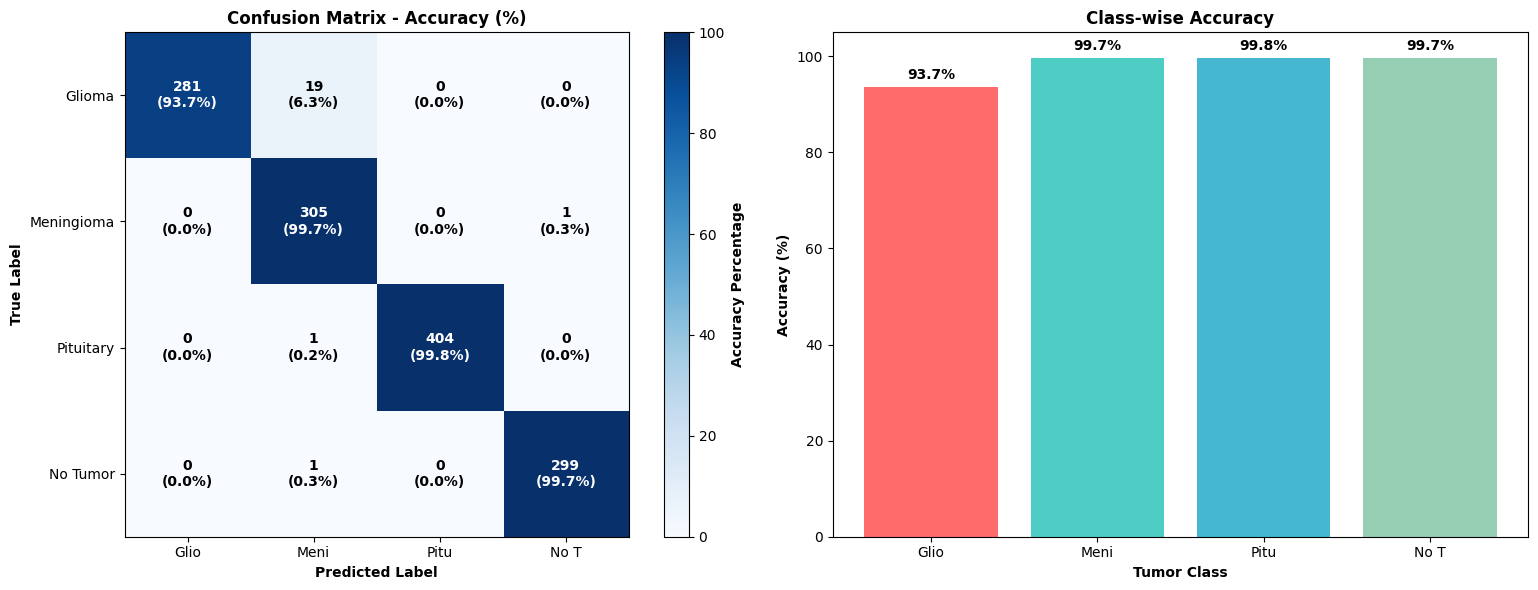

 PERFORMANCE SUMMARY
Overall Accuracy: 98.32%
Total Test Images: 1311


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Glioma       1.00      0.94      0.97       300
  Meningioma       0.94      1.00      0.97       306
   Pituitary       1.00      1.00      1.00       405
    No Tumor       1.00      1.00      1.00       300

    accuracy                           0.98      1311
   macro avg       0.98      0.98      0.98      1311
weighted avg       0.98      0.98      0.98      1311



In [42]:
# Create a NEW CELL for this visual confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# 📌 1. Generate Confusion Matrix
# test_labels → true labels from your dataset
# all_predictions → predicted labels from your model
cm = confusion_matrix(test_labels, all_predictions)

# Define your classes (adjust to match your dataset!)
class_names = ['Glioma', 'Meningioma', 'Pituitary', 'No Tumor']

# 📌 2. Create figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. CONFUSION MATRIX HEATMAP WITH PERCENTAGES
# Calculate percentages CORRECTLY
cm_percent = np.zeros_like(cm, dtype=float)
for i in range(len(class_names)):
    row_total = cm[i].sum()
    if row_total > 0:
        cm_percent[i] = cm[i] / row_total * 100
    else:
        cm_percent[i] = 0

# Create heatmap
im = ax1.imshow(cm_percent, cmap='Blues', vmin=0, vmax=100)
ax1.set_xticks(np.arange(len(class_names)))
ax1.set_yticks(np.arange(len(class_names)))
ax1.set_xticklabels([name[:4] for name in class_names])
ax1.set_yticklabels(class_names)
ax1.set_xlabel('Predicted Label', fontweight='bold')
ax1.set_ylabel('True Label', fontweight='bold')
ax1.set_title('Confusion Matrix - Accuracy (%)', fontweight='bold')

# Add text annotations with counts and percentages
for i in range(len(class_names)):
    for j in range(len(class_names)):
        text = f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)"
        ax1.text(j, i, text, ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white' if cm_percent[i, j] > 50 else 'black')

# Add colorbar
cbar = plt.colorbar(im, ax=ax1)
cbar.set_label('Accuracy Percentage', fontweight='bold')

# 2. CLASS ACCURACY BAR CHART (FIXED CALCULATION)
class_accuracies = []
for i in range(len(class_names)):
    correct = cm[i, i]
    total = cm[i].sum()
    if total > 0:
        accuracy = correct / total * 100
    else:
        accuracy = 0
    class_accuracies.append(accuracy)

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
bars = ax2.bar(range(len(class_names)), class_accuracies, color=colors)
ax2.set_xlabel('Tumor Class', fontweight='bold')
ax2.set_ylabel('Accuracy (%)', fontweight='bold')
ax2.set_title('Class-wise Accuracy', fontweight='bold')
ax2.set_xticks(range(len(class_names)))
ax2.set_xticklabels([name[:4] for name in class_names])
ax2.set_ylim(0, 105)

# Add value labels on bars
for bar, accuracy in zip(bars, class_accuracies):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{accuracy:.1f}%', ha='center', va='bottom',
             fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# 3. PERFORMANCE SUMMARY (WITH CORRECT OVERALL ACCURACY)
print(" PERFORMANCE SUMMARY")
print("=" * 40)
print(f"Overall Accuracy: {accuracy_score(test_labels, all_predictions)*100:.2f}%")
print(f"Total Test Images: {len(test_labels)}")
print()

# 4. CLASSIFICATION REPORT
print("\n" + "="*55)
print("CLASSIFICATION REPORT")
print("="*55)
print(classification_report(test_labels, all_predictions, target_names=class_names))
print("="*55)